In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import seaborn as sns
import xarray as xr
import cartopy.crs as ccrs
import netCDF4 as nc
import numpy as np

In [64]:
#load Mauna Loa and AQS data 
ds_1 = xr.open_dataset('/Users/gabrielagarcia/Desktop/Fall 2026/Geol 415/hw4/GEOS-CF_AirQuality_20180101_0030z.nc4', engine='netcdf4')
ds_1
aqs= "/Users/gabrielagarcia/Desktop/Fall 2026/Geol 415/hw3/LA_AQS_2023.csv"
ds_1_b= pd.read_csv(aqs)
maunaL = "/Users/gabrielagarcia/Desktop/Fall 2026/Geol 415/HW5/ManuaLoa_CO2.csv"
ds_2 = pd.read_csv(maunaL)
print(ds_1_b.head())

   State Code  County Code  Site Number  Parameter Code  POC  Latitude  \
0           6           37         1103           68103    1  34.06659   
1           6           37         1103           42602    3  34.06659   
2           6           37         1103           62201    1  34.06659   
3           6           37         1103           62101    1  34.06659   
4           6           37         1103           42603    1  34.06659   

   Longitude  Datum            Parameter Name Duration Description  ... AQI  \
0 -118.22688  WGS84   Ambient Min Temperature              24 HOUR  ...   .   
1 -118.22688  WGS84    Nitrogen dioxide (NO2)               1 HOUR  ...  16   
2 -118.22688  WGS84         Relative Humidity               1 HOUR  ...   .   
3 -118.22688  WGS84       Outdoor Temperature               1 HOUR  ...   .   
4 -118.22688  WGS84  Oxides of nitrogen (NOx)               1 HOUR  ...   .   

  Daily Criteria Indicator  Tribe Name  State Name  County Name    City Name  \


In [65]:
#find O3 and NO2 data and store it in variable 
O3= ds_1.O3
NO2= ds_1.NO2

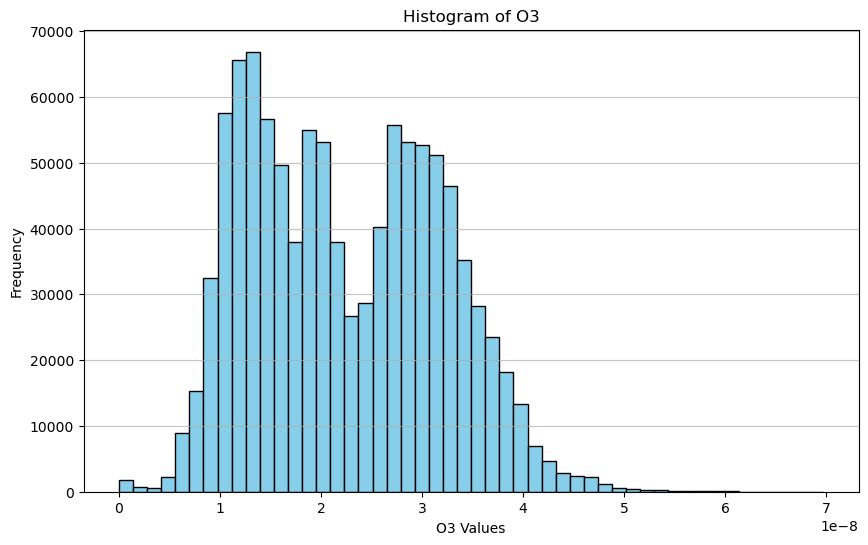

In [66]:
#Plot O3 data on histogram
plt.figure(figsize=(10, 6))
plt.hist(O3.values.ravel(), bins=50, color='skyblue', edgecolor='black')
#add labels and adjust grid transparency
plt.title('Histogram of O3')
plt.xlabel('O3 Values')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)

plt.show()

In [67]:
#Highest O3 values detected were around 6e-8 and the most frequent values were roughly between 1-1.5e-8.

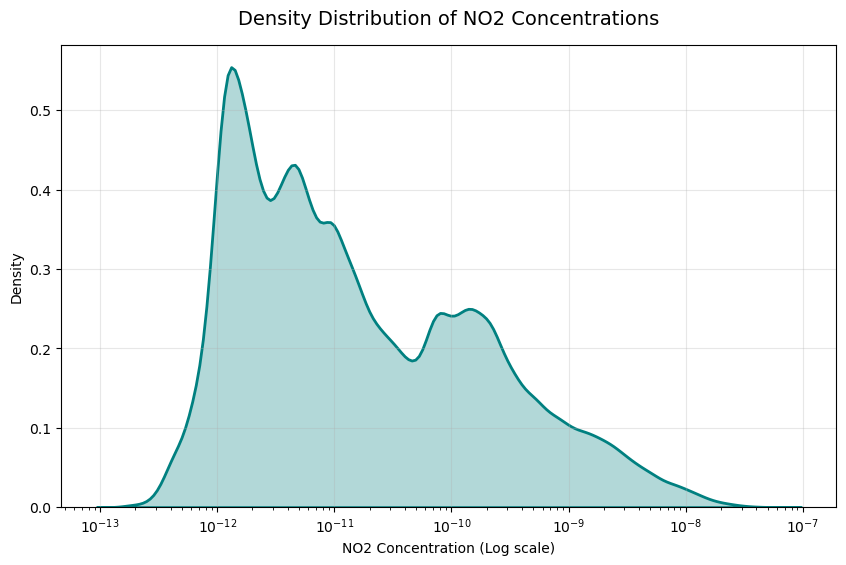

In [68]:
#make density plot with NO2 data
no2_flat = NO2.values.ravel()
no2_clean = no2_flat[~np.isnan(no2_flat)]
plt.figure(figsize=(10, 6))
sns.kdeplot(no2_clean, log_scale=True, color="teal", fill=True, alpha=0.3, linewidth=2)
# Labeling 
plt.title('Density Distribution of NO2 Concentrations', fontsize=14, pad=15)
plt.xlabel('NO2 Concentration (Log scale)')
plt.ylabel('Density')
plt.grid(axis='both', alpha=0.3)

plt.show()

In [69]:
#Most of the NO2 concentrations are around 10^-12-10^-11.

In [70]:
#date local instead of year
#put NO2 and O3 data into variables from csv file
O3_csv = ds_1_b[ds_1_b['Parameter Name'] == 'Ozone'].copy()

NO2_csv = ds_1_b[ds_1_b['Parameter Name'] == 'Nitrogen dioxide (NO2)'].copy()
#merge NO2 and O3 data 
O3_csv["Date (Local)"] = pd.to_datetime(O3_csv["Date (Local)"])
NO2_csv["Date (Local)"] = pd.to_datetime(NO2_csv["Date (Local)"])
df_all = O3_csv.merge(NO2_csv, on=["Date (Local)"])


In [71]:
#find how data is labeled
#print(df_all.columns)

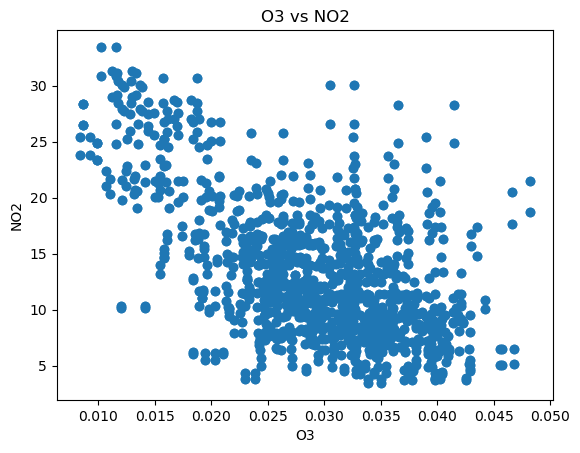

In [72]:
# make scatter plot
plt.scatter(df_all["Arithmetic Mean_x"], df_all["Arithmetic Mean_y"])

plt.xlabel("O3")
plt.ylabel("NO2")
plt.title("O3 vs NO2")
plt.show()

In [73]:
#In general there seems to be a trend of O3 decreasing when NO2 increases.

In [74]:
#make date colum datetime
O3_csv["Date (Local)"]= pd.to_datetime(O3_csv["Date (Local)"])
#store variables higher than 35ppb into a variable
O3_high= O3_csv[O3_csv["Arithmetic Mean"] >3.5e-8].copy()
#count the days where value above 35ppb per month
days_per_month = (
    O3_high.groupby(O3_high["Date (Local)"].dt.to_period("M"))["Date (Local)"]
    .apply(lambda x: x.dt.date.nunique())
)
days_per_month.index = days_per_month.index.astype(str)

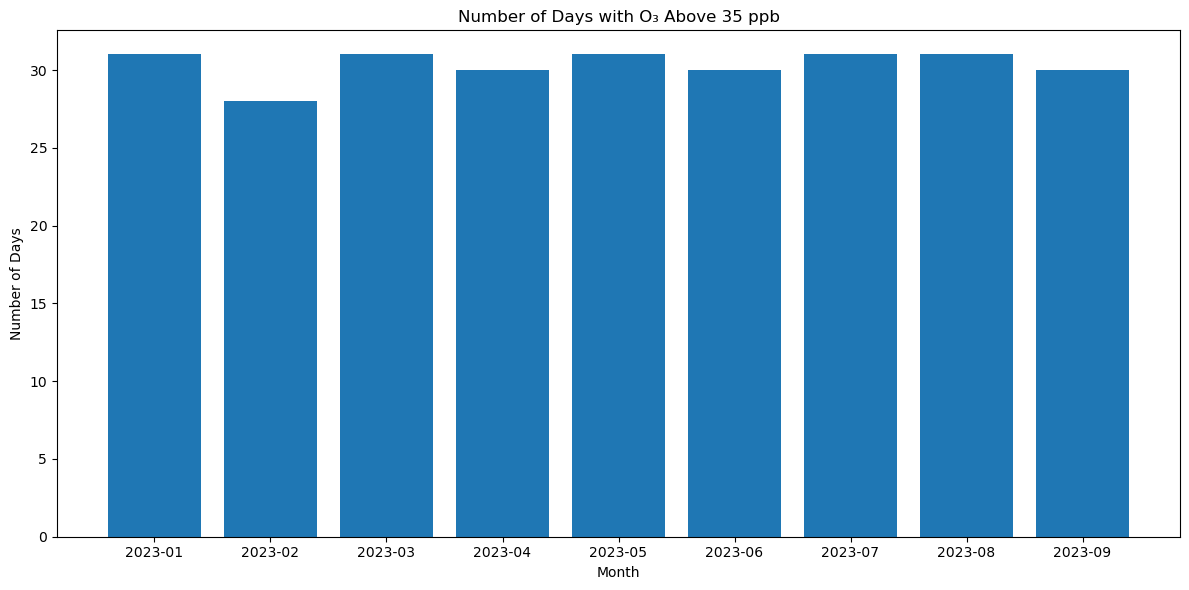

In [75]:
#make bar chart
plt.figure(figsize=(12, 6))

plt.bar(days_per_month.index, days_per_month.values)

plt.xlabel("Month")
plt.ylabel("Number of Days")
plt.title("Number of Days with O₃ Above 35 ppb")
plt.tight_layout()
plt.show()

In [76]:
#From the nine months of data detected, most days were about 35ppb of O3.

In [77]:
print (ds_2.head())

   year  month  decimal date  average  deseasonalized  ndays  sdev   unc
0  1958      3     1958.2027   315.70          314.43     -1 -9.99 -0.99
1  1958      4     1958.2877   317.45          315.16     -1 -9.99 -0.99
2  1958      5     1958.3699   317.51          314.71     -1 -9.99 -0.99
3  1958      6     1958.4548   317.24          315.14     -1 -9.99 -0.99
4  1958      7     1958.5370   315.86          315.18     -1 -9.99 -0.99


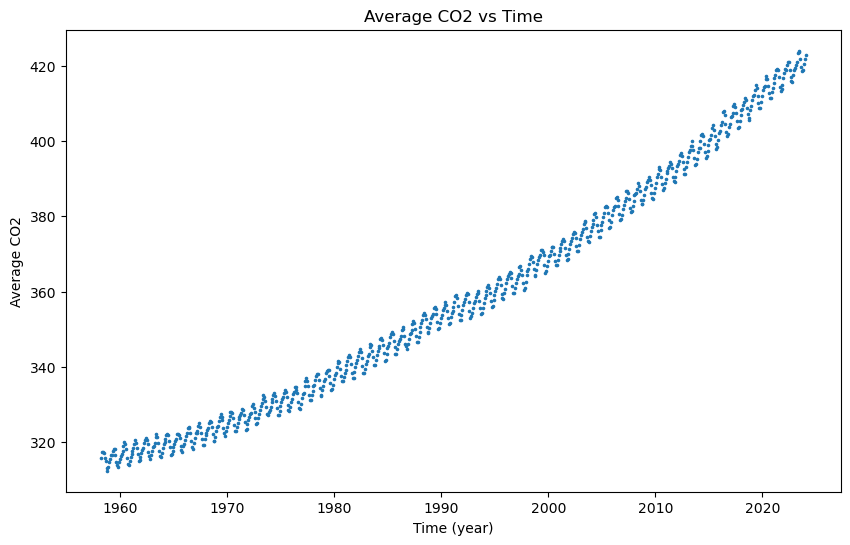

In [78]:
#make plot of average CO2 vs time from Mauna Loa data
plt.figure(figsize=(10, 6))
plt.scatter(ds_2["decimal date"], ds_2["average"], s=2.5)

plt.xlabel("Time (year)")
plt.ylabel("Average CO2")
plt.title("Average CO2 vs Time")
plt.show()

In [79]:
#CO2 concentrations have been increasing steadily with seasonal yearly oscillations.

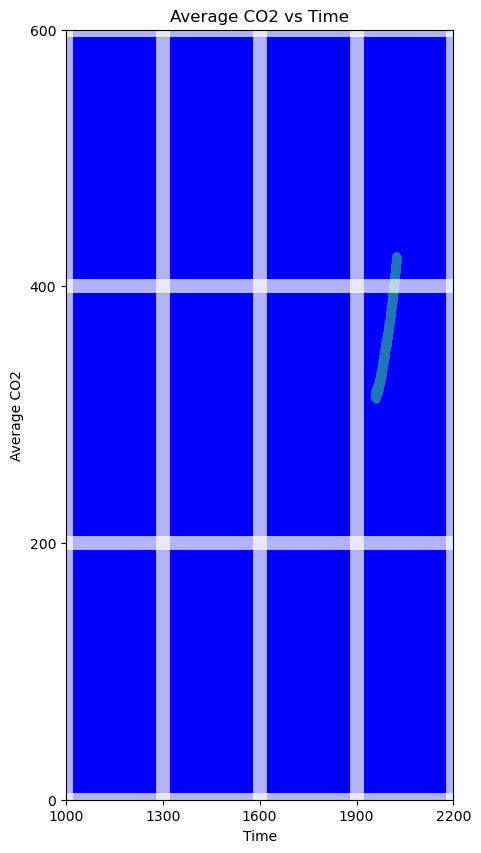

In [80]:
#not great scatterplot
plt.figure(figsize=(5, 10))
plt.scatter(ds_2["decimal date"], ds_2["average"], s=25)
#add background color
plt.gca().set_facecolor('blue')
#add grid lines
plt.grid(True, color='white', linestyle='-', linewidth=10, alpha=0.7)
#plot labels
plt.xlabel("Time")
plt.ylabel("Average CO2")
plt.title("Average CO2 vs Time")
plt.yticks(range(0, 800, 200))
plt.xticks(range(1000, 2500, 300))
plt.show()

In [81]:
#Same as last plot but harder to understand the range of time and CO2 concentrations captured.